# Comparação Estatística: Turma A vs. Turma B (10 Alunos Cada)

Demonstração prática por que **olhar apenas para a média pode enganar** na tomada de decisões.

Vamos analisar duas turmas fictícias com **10 alunos cada**, ambas com **média geral igual a 7,0**, mas com realidades completamente opostas em relação à homogeneidade e ao risco de reprovação:
* **Turma A (Homogênea):** Notas muito próximas da média.
* **Turma B (Heterogênea):** Metade com nota máxima (10,0) e metade com nota baixa (4,0).

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Definindo os conjuntos de notas (10 alunos por turma)
turma_a = np.array([6.8, 6.9, 6.9, 7.2, 8.6, 7.0, 8.0, 7.1, 7.5, 9.6])
turma_b = np.array([4.0, 4.0, 5.5, 4.0, 6.0, 10.0, 8.9, 10.0, 9.0, 10.0])

print('Notas Turma A:', turma_a)
print('Notas Turma B:', turma_b)

Notas Turma A: [6.8 6.9 6.9 7.2 8.6 7.  8.  7.1 7.5 9.6]
Notas Turma B: [ 4.   4.   5.5  4.   6.  10.   8.9 10.   9.  10. ]


## 1. Cálculo das Medidas Estatísticas (População Completa: `ddof=0`)

Como estamos analisando todos os 10 alunos de cada turma, tratamos cada conjunto como uma **população completa** (`ddof=0`).

In [5]:
def calcular_metricas(notas, nota_corte=7.0):
    media = np.mean(notas)
    amplitude = np.max(notas) - np.min(notas)
    variancia = np.var(notas, ddof=0)
    desvio_padrao = np.std(notas, ddof=0)
    cv = (desvio_padrao / media) * 100
    abaixo_corte = np.sum(notas < nota_corte)
    reprovacao_critica = np.sum(notas < 5.0)
    return {
        'Média Aritmética': round(media, 2),
        'Amplitude Total': round(amplitude, 2),
        'Variância (V)': round(variancia, 3),
        'Desvio Padrão (DP)': round(desvio_padrao, 2),
        'Coef. Variação (CV %)': round(cv, 2),
        'Alunos < 7,0': int(abaixo_corte),
        'Reprovados Críticos (< 5,0)': int(reprovacao_critica)
    }

resultados = pd.DataFrame({
    'Turma A (Homogênea)': calcular_metricas(turma_a),
    'Turma B (Heterogênea)': calcular_metricas(turma_b)
})

resultados

,Turma A (Homogênea),Turma B (Heterogênea)
Média Aritmética,7.560,7.140
Amplitude Total,2.800,6.000
Variância (V),0.754,6.466
Desvio Padrão (DP),0.870,2.540
Coef. Variação (CV %),11.490,35.620
"Alunos < 7,0",3.000,5.000
"Reprovados Críticos (< 5,0)",0.000,3.000


## 2. Visualização Gráfica do Contraste de Dispersão

O gráfico abaixo compara as notas individuais dos 10 alunos de cada turma em relação à linha da média geral (**7,0**).

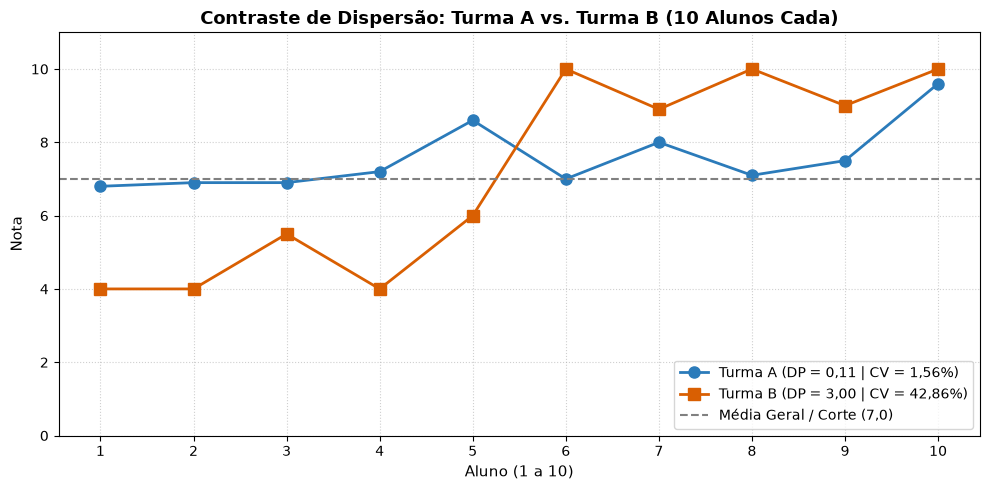

In [6]:
alunos = np.arange(1, 11)

plt.figure(figsize=(10, 5))
plt.plot(alunos, turma_a, marker='o', linewidth=2, markersize=8, color='#2b7bba', label='Turma A (DP = 0,11 | CV = 1,56%)')
plt.plot(alunos, turma_b, marker='s', linewidth=2, markersize=8, color='#d95f02', label='Turma B (DP = 3,00 | CV = 42,86%)')
plt.axhline(7.0, color='gray', linestyle='--', linewidth=1.5, label='Média Geral / Corte (7,0)')

plt.title('Contraste de Dispersão: Turma A vs. Turma B (10 Alunos Cada)', fontsize=13, fontweight='bold')
plt.xlabel('Aluno (1 a 10)', fontsize=11)
plt.ylabel('Nota', fontsize=11)
plt.xticks(alunos)
plt.ylim(0, 11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 3. Conclusão da Análise

* **Turma A:** Possui baixíssima dispersão (`CV = 1,56%`). A média **7,0** representa fielmente o desempenho da sala inteira, sem casos críticos de reprovação.
* **Turma B:** Possui altíssima dispersão (`CV = 42,86%`). O desvio padrão (**3,00 pontos**) é cerca de **27 vezes maior** que o da Turma A, expondo que **50% dos alunos (5 de 10)** estão em situação crítica de reprovação com nota **4,0**.